# Buổi A2: Dữ liệu là một cái bảng, và bảng nào cũng có tì vết

**Hiện trường.** Chị Hạnh là điều dưỡng trưởng của một khoa. Mỗi tuần chị chỉ có **20 suất theo dõi sát** và phải chọn 20 bệnh nhân có nguy cơ tiến triển nặng nhất trong số 442 người đang điều trị. Chọn đúng thì người cần được chăm kịp thời. Chọn nhầm thì suất quý rơi vào người không cần, còn người cần thì bị bỏ sót.

Chị nhờ cậu Tí (cái máy ở buổi A1) giúp xếp hạng. Nhưng có một chuyện: cuốn sổ chị nhận được là **bản photo từ khoa khác**, có chỗ mờ, chỗ trùng, chỗ ai đó gõ nhầm.

**Câu hỏi của buổi này:** *trước khi tin bất cứ con số nào máy đưa ra, ta phải kiểm tra cuốn sổ thế nào? Và một ô nhập sai có thể làm hỏng quyết định của chị Hạnh đến mức nào?*

**Mindset của người làm dữ liệu:** dữ liệu là **nhân chứng**. Nhân chứng có thể nhớ nhầm, bỏ sót, hoặc khai trùng. Việc đầu tiên là *thẩm vấn* nhân chứng, chưa phải xây mô hình.

**Chuẩn bị:** không cần tải file. Buổi này dùng lại cú pháp đã học ở A1 mà không giải thích lại; chỉ phần mới mới có giải thích.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Mở sổ ra: ta đang cầm thứ gì? |
| Chặng 1 | Dòng, cột, và hai vai `X` với `y` |
| Chặng 2 | Con số nào là "lượng", con số nào chỉ là "nhãn"? |
| Chặng 3 | Ô trống: máy không chịu đọc, ta xử lý thế nào? |
| Chặng 4 | Dòng trùng và ô gõ nhầm: một ô sai làm hỏng đến đâu? |
| Chặng 5 | Công thức làm sạch, và đo hậu quả bằng quyết định của chị Hạnh |

## Chặng 0: Mở sổ ra, hỏi bốn câu đầu tiên

**Câu hỏi:** trước khi làm gì khác, một người làm dữ liệu giỏi luôn hỏi: *có bao nhiêu dòng, bao nhiêu cột, mỗi cột là gì, có ô nào trống không?*

Bản sổ **gốc** (sạch) là bộ dữ liệu quen thuộc từ buổi A1.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
original = load_diabetes(as_frame=True, scaled=False).frame
original.shape

(442, 11)

**Giải thích từng dòng**

- `from sklearn.datasets import load_diabetes`: (đã học ở A1) lấy hàm mở bộ dữ liệu.
- `from sklearn.linear_model import LinearRegression`: (đã học ở A1) lấy cỗ máy hồi quy tuyến tính.
- `original = load_diabetes(as_frame=True, scaled=False).frame`: mở bộ dữ liệu và lấy luôn cái bảng, đặt tên `original` (bản gốc). Hai dòng trước ở A1 gộp lại thành một dòng.
- `original.shape`: `shape` (hình dạng) cho biết bảng có **(số dòng, số cột)**. Không có ngoặc tròn phía sau vì `shape` là một thuộc tính, không phải chức năng.

In [3]:
original.info()

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


**Giải thích từng dòng**

- `original.info()`: `info()` in bản "lý lịch" của bảng: tên từng cột, **số ô có dữ liệu** (`Non-Null Count`) và **kiểu dữ liệu** (`Dtype`). Đây là lệnh đáng gõ đầu tiên với mọi bảng mới.

In [4]:
original.describe().round(1)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,442.0,442.0,442.0,442.0,442.0,442.0,442.0,442.0,442.0,442.0,442.0
mean,48.5,1.5,26.4,94.6,189.1,115.4,49.8,4.1,4.6,91.3,152.1
std,13.1,0.5,4.4,13.8,34.6,30.4,12.9,1.3,0.5,11.5,77.1
min,19.0,1.0,18.0,62.0,97.0,41.6,22.0,2.0,3.3,58.0,25.0
25%,38.2,1.0,23.2,84.0,164.2,96.0,40.2,3.0,4.3,83.2,87.0
50%,50.0,1.0,25.7,93.0,186.0,113.0,48.0,4.0,4.6,91.0,140.5
75%,59.0,2.0,29.3,105.0,209.8,134.5,57.8,5.0,5.0,98.0,211.5
max,79.0,2.0,42.2,133.0,301.0,242.4,99.0,9.1,6.1,124.0,346.0


**Giải thích từng dòng**

- `original.describe().round(1)`: `describe()` tóm tắt từng cột bằng 8 con số: `count` (số ô có dữ liệu), `mean` (trung bình), `std` (độ phân tán), `min` và `max` (nhỏ nhất, lớn nhất), cùng ba mốc `25%`, `50%`, `75%` (phân vị, `50%` là số ở chính giữa, còn gọi là **trung vị**). `.round(1)` làm tròn một chữ số thập phân cho dễ đọc.

**Cách đọc**

- **Con số:** 442 dòng, 11 cột; mỗi cột đều có đủ 442 ô (không ô nào trống); tất cả đều là kiểu số thập phân `float64`. Tuổi từ 19 đến 79, BMI từ 18 đến 42, điểm tiến triển từ 25 đến 346.
- **Bức tranh:** đây là bản gốc sạch như một cuốn sổ chép tay nắn nót. Mỗi dòng là *một bệnh nhân*, mỗi cột là *một thứ đã đo*. Hãy nhớ trạng thái này, vì lát nữa cuốn sổ photo sẽ trông rất khác.
- **Một điều ta chưa biết:** `info()` nói mọi cột đều là số thập phân. Vậy có phải cột nào cũng là một "lượng" có thể cộng trừ được không? Câu trả lời ở chặng 2.

## Chặng 1: Dòng, cột, và hai vai `X` với `y`

**Câu hỏi:** trong một bảng, thứ nào máy được phép *nhìn*, thứ nào máy phải *đoán*?

Quy ước chung của cả khóa: **mỗi dòng là một ca**, **mỗi cột là một thứ đã đo về ca đó**. Với bài toán của chị Hạnh, cột `target` (điểm tiến triển sau 1 năm) là thứ cần đoán. Mọi cột còn lại là thứ máy được phép nhìn.

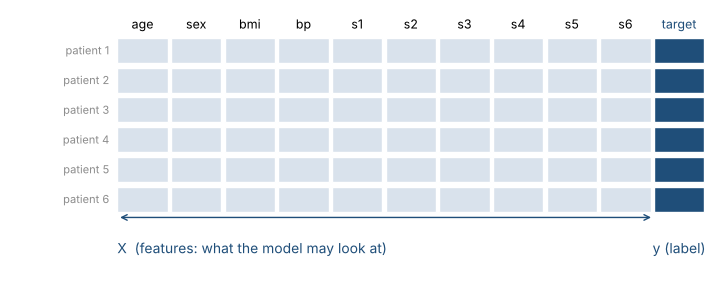

In [5]:
# Decorative diagram: just run it, no need to read the code line by line.
cols = list(original.columns)
fig, ax = plt.subplots(figsize=(9, 3.4))
for j, c in enumerate(cols):
    for i in range(6):
        ax.add_patch(plt.Rectangle((j, -i), 0.94, 0.84, fc=BLUE if c == "target" else "#D9E2EC", ec="white"))
    ax.text(j + 0.47, 1.15, c, ha="center", fontsize=9, color=BLUE if c == "target" else "black")
for i in range(6):
    ax.text(-0.15, -i + 0.42, f"patient {i+1}", ha="right", va="center", fontsize=8, color=GRAY)
ax.annotate("X  (features: what the model may look at)", xy=(0, -5.5), xytext=(0, -6.4), fontsize=10, color=BLUE)
ax.annotate("", xy=(0, -5.2), xytext=(10, -5.2), arrowprops=dict(arrowstyle="<->", color=BLUE))
ax.text(10.47, -6.4, "y (label)", ha="center", fontsize=10, color=BLUE)
ax.set_xlim(-2, 11); ax.set_ylim(-7, 1.8); ax.axis("off")
plt.show()

In [6]:
X = original.drop(columns="target")
y = original["target"]
print(X.shape, y.shape)

(442, 10) (442,)


**Giải thích từng dòng**

- `X = original.drop(columns="target")`: `drop(columns=...)` **bỏ cột có tên chỉ định** và trả về phần còn lại. Vậy `X` là bảng 10 cột (mọi thứ trừ `target`). Bảng gốc `original` không bị đổi.
- `y = original["target"]`: (đã học ở A1) `y` là cột đáp án.
- `print(X.shape, y.shape)`: kiểm tra hình dạng: `X` là (442, 10) tức bảng, `y` là (442,) tức một cột đơn. In hai thứ cách nhau dấu phẩy thì `print` tự thêm khoảng trắng.

Từ A1 ta chỉ cho máy nhìn **một** cột. Cách dùng với **10** cột hoàn toàn y như vậy: `fit(X, y)` rồi `predict(...)`. Máy sẽ học mỗi cột một độ dốc thay vì một.

In [7]:
def miss(model, X, y):
    return (y - model.predict(X)).abs().mean()

model_ref = LinearRegression().fit(X, y)
print(f"10 columns: average miss {miss(model_ref, X, y):.1f} points (1 column in A1: 51.8)")

10 columns: average miss 43.3 points (1 column in A1: 51.8)


**Giải thích từng dòng**

- `def miss(model, X, y):`: tự định nghĩa chức năng `miss` (đã học `def` ở A1) để dùng lại nhiều lần: nhận một máy, bảng đề, cột đáp án.
- `return (y - model.predict(X)).abs().mean()`: (đã học ở A1) sai lệch trung bình: đáp án trừ dự đoán, bỏ dấu, lấy trung bình.
- `model_ref = LinearRegression().fit(X, y)`: tạo máy và cho học luôn trong một dòng (nối `.fit` ngay sau dấu ngoặc). `model_ref` là máy **tham chiếu**, học từ bản sổ gốc sạch.
- `print(f"10 columns: average miss {miss(model_ref, X, y):.1f} points ...")`: in sai lệch của máy tham chiếu.

**Cách đọc**

- **Con số:** thêm 9 cột thì sai lệch giảm từ khoảng 52 xuống khoảng 43. Thêm thông tin thì máy đoán tốt hơn.
- **Bức tranh:** máy giờ nhìn được tuổi, huyết áp, các chỉ số xét nghiệm... chứ không chỉ BMI. Giống người điều dưỡng xem hồ sơ đầy đủ thay vì chỉ nhìn cân nặng.

Bây giờ là **cái bẫy kinh điển** của người mới. Điều gì xảy ra nếu ta lỡ để cột đáp án lọt vào đề bài?

In [8]:
X_leak = original.copy()
model_leak = LinearRegression().fit(X_leak, y)
print(f"Average miss: {miss(model_leak, X_leak, y):.1f} points")

Average miss: 0.0 points


**Giải thích từng dòng**

- `X_leak = original.copy()`: `copy()` tạo một **bản sao** của bảng. Bản sao này còn nguyên cột `target`: đề bài đã chứa luôn đáp án.
- `model_leak = LinearRegression().fit(X_leak, y)`: cho máy học trên bảng có lẫn đáp án.
- `print(f"Average miss: {miss(model_leak, X_leak, y):.1f} points")`: in sai lệch.

**Cách đọc**

- **Con số:** sai lệch bằng **0,0**. Một máy đoán hoàn hảo!
- **Bức tranh:** đẹp đến mức phải nghi ngờ. Máy không thông minh, nó chỉ *chép đáp án nằm sẵn trong đề*. Ngoài đời, bệnh nhân mới chưa có điểm sau 1 năm, nên máy này vô dụng. Hiện tượng này gọi là **rò rỉ dữ liệu** (data leakage).
- **Quy tắc nghề:** *điểm số hoàn hảo là dấu hiệu cảnh báo, không phải chiến thắng.* Luôn hỏi: "lúc cần đoán ngoài đời, mình có những cột này trong tay chưa?"

**Mang về chặng 1:** mỗi dòng là một ca, mỗi cột là một thứ đã đo. `X` là bảng chứa những cột máy được nhìn, `y` là cột cần đoán, và `y` tuyệt đối không được nằm trong `X`.

## Chặng 2: Con số nào là "lượng", con số nào chỉ là "nhãn"?

**Câu hỏi:** `info()` nói mọi cột đều là số thập phân. Vậy cột nào cũng cộng trừ được, so lớn nhỏ được?

Mẹo kiểm tra nhanh: đếm xem mỗi cột có bao nhiêu **giá trị khác nhau**. Cột đo thật (như BMI) có rất nhiều giá trị khác nhau. Cột chỉ là mã số (như giới tính) chỉ có vài giá trị.

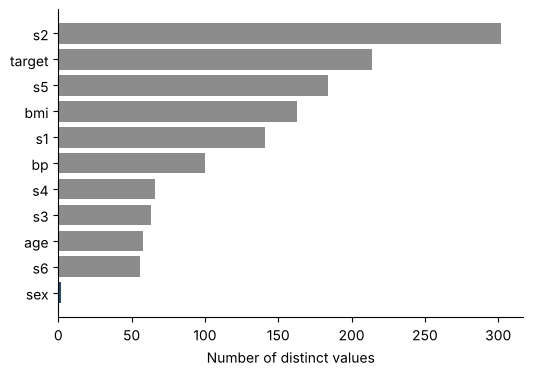

In [9]:
distinct = original.nunique().sort_values()
plt.barh(distinct.index, distinct.values, color=[BLUE if n <= 5 else GRAY for n in distinct.values])
plt.xlabel("Number of distinct values")
plt.show()

**Giải thích từng dòng**

- `distinct = original.nunique().sort_values()`: `nunique()` đếm số giá trị khác nhau của **mỗi cột**, trả về một dãy số có tên cột làm nhãn. `sort_values()` xếp dãy đó từ nhỏ đến lớn.
- `plt.barh(distinct.index, distinct.values, color=[BLUE if n <= 5 else GRAY for n in distinct.values])`: `barh` là biểu đồ cột **nằm ngang** (h là horizontal). `distinct.index` là tên cột, `distinct.values` là độ dài thanh. Phần `color=[... for n in ...]` tô xanh những cột có không quá 5 giá trị khác nhau, còn lại tô xám.
- `plt.xlabel("Number of distinct values")`: ghi tên trục ngang.
- `plt.show()`: hiện hình.

**Cách đọc**

- **Con số:** cột `sex` chỉ có **2** giá trị khác nhau, trong khi `bmi` có 163, `s2` có 302.
- **Bức tranh:** `sex` được lưu thành số 1 và 2, nhưng đó là **nhãn nhóm**, không phải lượng đo. Không có nghĩa "nhóm 2 gấp đôi nhóm 1". Máy và pandas không biết điều này; chúng thấy số thì coi là số. Người làm dữ liệu phải tự biết.
- **Vì sao quan trọng:** với hai nhóm (như `sex`), dùng 1 và 2 vẫn ổn: máy chỉ học "chênh lệch giữa hai nhóm". Nhưng nếu có ba nhóm trở lên (ví dụ khu vực A, B, C mã là 1, 2, 3), máy sẽ hiểu nhầm C "lớn hơn" B. Cách chữa (mã hóa one-hot) sẽ học ở buổi B3.
- **Còn một loại cột nữa chưa gặp:** cột chữ như "Hà Nội", "nam"/"nữ". `LinearRegression` **không đọc được chữ**, phải đổi thành số trước khi đưa vào `X`. Bộ dữ liệu này không có cột chữ nên ta để dành đến B3.

**Mang về chặng 2:** nhìn kiểu dữ liệu chưa đủ. Phải hỏi *"cột này là một lượng đo, hay chỉ là mã của một nhóm?"* Số cột có ít giá trị khác nhau thường là mã nhóm.

## Chặng 3: Ô trống, máy không chịu đọc

**Câu hỏi:** nếu cuốn sổ có chỗ mờ không đọc được, máy phản ứng ra sao, và ta xử lý thế nào?

**Thú thật:** bản gốc không có ô trống nào. Để luyện tay, mình **tự làm bẩn có chủ đích** một bản photo (gọi là `ledger`): xóa ngẫu nhiên 22 ô ở mỗi cột `bmi`, `bp`, `s6`, thêm vài dòng trùng, và gõ nhầm một ô. Mọi vết bẩn đều do ta tạo ra, nên ta biết chính xác đáp án đúng để so lại.

In [10]:
rng = np.random.default_rng(0)
ledger = original.copy()
for col in ["bmi", "bp", "s6"]:
    blank_rows = rng.choice(len(ledger), size=22, replace=False)
    ledger.loc[blank_rows, col] = np.nan

**Giải thích từng dòng**

- `rng = np.random.default_rng(0)`: tạo bộ sinh số ngẫu nhiên. Số `0` là **hạt giống** (seed): cùng hạt giống thì cùng chuỗi ngẫu nhiên, nên lần nào chạy bạn cũng ra đúng kết quả như trong bài. Hạt giống giống một bộ số cố định, đi đâu dùng cũng ra cùng kết quả.
- `ledger = original.copy()`: bản sao để làm bẩn, bản gốc vẫn nguyên.
- `for col in ["bmi", "bp", "s6"]:`: lặp qua ba cột sẽ bị xóa ô.
- `blank_rows = rng.choice(len(ledger), size=22, replace=False)`: chọn ngẫu nhiên 22 vị trí dòng khác nhau. `replace=False` nghĩa là không chọn trùng một dòng hai lần.
- `ledger.loc[blank_rows, col] = np.nan`: `.loc[các dòng, cột] = giá trị` **gán giá trị** cho đúng các ô đó. `np.nan` (NaN, viết tắt của Not a Number) là cách máy tính ghi "ô này trống".

In [11]:
ledger.loc[100, "bmi"] = 321.0
ledger = pd.concat([ledger, ledger.iloc[[5, 50, 200, 300]]], ignore_index=True)
ledger.shape

(446, 11)

**Giải thích từng dòng**

- `ledger.loc[100, "bmi"] = 321.0`: dòng 100 vốn có BMI 32,1; ta gõ nhầm thành 321.0 (quên dấu thập phân, một lỗi rất đời thường).
- `ledger = pd.concat([ledger, ledger.iloc[[5, 50, 200, 300]]], ignore_index=True)`: `iloc[[...]]` lấy 4 dòng theo **vị trí**. `pd.concat([A, B])` **nối B xuống dưới A**. Vậy 4 dòng này xuất hiện hai lần (dòng trùng). `ignore_index=True` đánh số lại từ 0.
- `ledger.shape`: giờ bảng có 446 dòng: 442 gốc cộng 4 dòng trùng.

In [12]:
ledger.isna().sum()

age        0
sex        0
bmi       22
bp        22
s1         0
s2         0
s3         0
s4         0
s5         0
s6        22
target     0
dtype: int64

**Giải thích từng dòng**

- `ledger.isna().sum()`: `isna()` biến bảng thành bảng Đúng/Sai (Đúng là ô trống). `sum()` cộng theo từng cột (Đúng tính là 1), ra **số ô trống của mỗi cột**. Đây là cách đếm ô trống chuẩn.

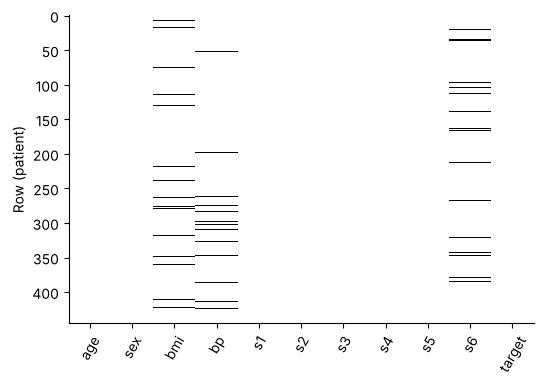

In [13]:
plt.imshow(ledger.isna(), aspect="auto", cmap="gray_r", interpolation="nearest")
plt.xticks(range(ledger.shape[1]), ledger.columns, rotation=60)
plt.ylabel("Row (patient)")
plt.show()

**Giải thích từng dòng**

- `plt.imshow(ledger.isna(), aspect="auto", cmap="gray_r", interpolation="nearest")`: `imshow` vẽ bảng thành một **bức ảnh ô vuông**: ô trống tô đen (`gray_r` là thang xám đảo, Đúng ra màu đậm), ô có dữ liệu để trắng. `aspect="auto"` cho ảnh giãn vừa khung. `interpolation="nearest"` giữ ô sắc nét, không làm mờ.
- `plt.xticks(range(ledger.shape[1]), ledger.columns, rotation=60)`: gắn tên cột lên trục ngang, xoay chữ 60 độ cho khỏi chồng nhau.
- `plt.ylabel("Row (patient)")`: ghi tên trục dọc.

**Cách đọc**

- **Con số:** ba cột `bmi`, `bp`, `s6` mỗi cột có 22 ô trống, các cột khác đầy đủ.
- **Bức tranh:** ảnh cho thấy ô trống rải rác như vết mực ố trên trang giấy. Nhìn thế này thấy ngay *chỗ nào thiếu*, *thiếu rải rác hay thiếu thành mảng*. Nếu vết đen dồn thành mảng (ví dụ cả một đợt khám), đó là dấu hiệu có chuyện hệ thống chứ không phải ngẫu nhiên.

Giờ thử đưa bảng này cho máy:

In [14]:
try:
    LinearRegression().fit(ledger.drop(columns="target"), ledger["target"])
except ValueError as err:
    print("Error:", str(err)[:60])

Error: Input X contains NaN.
LinearRegression does not accept missi


**Giải thích từng dòng**

- `try:`: `try` nghĩa là "thử làm điều này", cho phép ta **bắt lỗi** thay vì để chương trình dừng đỏ lòm.
- `LinearRegression().fit(ledger.drop(columns="target"), ledger["target"])`: cho máy học từ bảng có ô trống.
- `except ValueError as err:`: `except` nghĩa là "nếu gặp lỗi loại `ValueError` thì làm như sau", và đặt tên lỗi là `err`.
- `print("Error:", str(err)[:60])`: in 60 ký tự đầu của thông báo lỗi. `[:60]` là cách cắt lấy 60 ký tự đầu của một chuỗi chữ.

**Cách đọc:** máy báo lỗi và từ chối học, vì cách tính của hồi quy tuyến tính không biết làm gì với ô trống. Có hai hướng xử lý thông dụng:

| Hướng | Cách làm | Được | Mất |
|---|---|---|---|
| **Bỏ** | xóa mọi dòng có ô trống (`dropna()`) | đơn giản, không bịa số | mất nhiều ca, dù chỉ thiếu 1 ô |
| **Điền** | thay ô trống bằng một con số hợp lý, ví dụ trung vị của cột (`fillna()`) | giữ đủ số ca | điền sai thì thêm nhiễu |

Xem cái giá của việc "bỏ":

In [15]:
kept = ledger.dropna()
print(f"Rows: {len(ledger)} -> {len(kept)} (lost {len(ledger) - len(kept)} patients)")

Rows: 446 -> 381 (lost 65 patients)


**Giải thích từng dòng**

- `kept = ledger.dropna()`: `dropna()` xóa mọi dòng có **ít nhất một** ô trống, trả về bảng còn lại.
- `print(f"Rows: {len(ledger)} -> {len(kept)} (lost {len(ledger) - len(kept)} patients)")`: `len(...)` đếm số dòng. In số dòng trước, sau, và số bệnh nhân mất đi.

**Cách đọc**

- **Con số:** chỉ vì 66 ô trống (22 ô x 3 cột) mà ta mất **65 dòng**, tức gần 15% số bệnh nhân.
- **Bức tranh:** một ô mờ làm vứt cả bệnh án. Khi dữ liệu ít, cách này quá tốn. Còn "điền" thì ta cần chọn con số điền. Chặng 5 sẽ so hai cách bằng chính quyết định của chị Hạnh.
- **Điều cần nhớ khi điền:** trung vị phải tính **chỉ từ tập học**, không được nhìn tập thi (sẽ học kỹ ở A4). Trong buổi này ta chưa chia tập thi nên tạm tính trên cả bảng.

**Mang về chặng 3:** `LinearRegression` buộc phải xử lý ô trống trước. Hai hướng là bỏ dòng (`dropna`) hoặc điền số (`fillna`), mỗi hướng có cái giá riêng.

## Chặng 4: Dòng trùng và ô gõ nhầm

**Câu hỏi:** những lỗi *không làm máy báo lỗi* mới là nguy hiểm nhất. Làm sao phát hiện chúng?

Dòng trùng và ô gõ nhầm đều là số hợp lệ, máy vẫn học bình thường mà không ai báo gì.

In [16]:
print("Duplicate rows:", ledger.duplicated().sum())
print("Largest BMI in ledger:", ledger["bmi"].max())

Duplicate rows: 4
Largest BMI in ledger: 321.0


**Giải thích từng dòng**

- `print("Duplicate rows:", ledger.duplicated().sum())`: `duplicated()` đánh dấu Đúng cho dòng **giống hệt một dòng đã xuất hiện trước đó**. `sum()` đếm số dòng trùng.
- `print("Largest BMI in ledger:", ledger["bmi"].max())`: `max()` lấy giá trị lớn nhất của cột. Đây là cách rẻ nhất để bắt số vô lý: so với những gì ta biết về đời thực.

Phát hiện ra 4 dòng trùng và một BMI 321 (một người có BMI 321 là điều không thể). Nhưng nếu ta không để ý và cho máy học luôn thì sao? Mình thử với cách đơn giản nhất, một cột BMI như ở A1, để *nhìn thấy* tác hại:

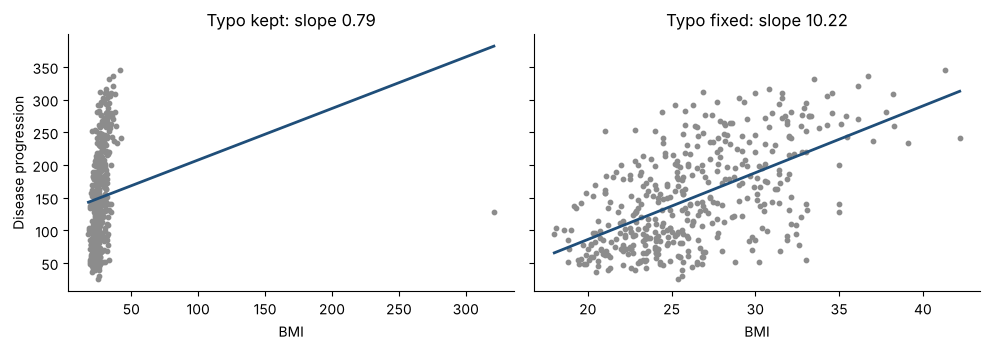

In [17]:
rows = ledger.dropna(subset=["bmi"])
fixed = rows[rows["bmi"] < 60]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, table, title in [(axes[0], rows, "Typo kept"), (axes[1], fixed, "Typo fixed")]:
    m = LinearRegression().fit(table[["bmi"]], table["target"])
    xs = pd.DataFrame({"bmi": [table["bmi"].min(), table["bmi"].max()]})
    ax.scatter(table["bmi"], table["target"], s=10, color=GRAY)
    ax.plot(xs["bmi"], m.predict(xs), color=BLUE, linewidth=2)
    ax.set_title(f"{title}: slope {m.coef_[0]:.2f}")
    ax.set_xlabel("BMI")
axes[0].set_ylabel("Disease progression")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `rows = ledger.dropna(subset=["bmi"])`: bỏ riêng các dòng thiếu BMI (`subset=[...]` giới hạn chỉ nhìn cột chỉ định). Ở đây ta chỉ cần cột `bmi` nên không cần bỏ vì thiếu cột khác.
- `fixed = rows[rows["bmi"] < 60]`: `rows[điều kiện]` **lọc dòng**: giữ lại những dòng thỏa điều kiện. Ở đây giữ BMI nhỏ hơn 60, tức bỏ dòng gõ nhầm.
- `fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)`: tạo khung hình 1 hàng 2 ô con. `sharey=True` bắt hai ô dùng chung thang trục dọc để so sánh công bằng.
- `for ax, table, title in [(axes[0], rows, "Typo kept"), (axes[1], fixed, "Typo fixed")]:`: lặp qua hai trường hợp, mỗi vòng nhận bộ ba (ô vẽ, bảng, tiêu đề).
- `m = LinearRegression().fit(table[["bmi"]], table["target"])`: mỗi trường hợp huấn luyện một máy riêng.
- `xs = pd.DataFrame({"bmi": [table["bmi"].min(), table["bmi"].max()]})`: hai đầu mút để vẽ đường thẳng, lấy từ chính bảng đang xét.
- `ax.scatter(...); ax.plot(...)`: (đã học ở A1) vẽ điểm và đường, nhưng gọi trên từng ô `ax` thay vì `plt`.
- `ax.set_title(f"{title}: slope {m.coef_[0]:.2f}")`: `set_title` đặt tiêu đề cho ô, kèm độ dốc đã học.
- `ax.set_xlabel("BMI"); axes[0].set_ylabel(...)`: ghi tên trục (cách gọi trên ô con là `set_xlabel`, `set_ylabel`).

**Cách đọc**

- **Con số:** khi giữ dòng gõ nhầm, độ dốc rơi từ khoảng 10,2 xuống chỉ còn khoảng 0,8; sau khi sửa, độ dốc về lại 10,2.
- **Bức tranh:** ở ô trái, chỉ **một chấm** nằm xa tít bên phải (BMI 321) đã kéo cả đường thẳng xoay phẳng đi, như một người nặng ký ngồi một đầu bập bênh. Đám mây thật của 440 người bị ép chật ở góc trái, nhìn không ra xu hướng. Ô phải sau khi bỏ chấm đó, bức tranh quay lại bình thường.
- **Bài học:** một ô sai đủ làm máy kết luận *"BMI không liên quan gì đến bệnh"*, hoàn toàn sai sự thật. Máy không biết 321 là vô lý, chỉ người mới biết.

**Mang về chặng 4:** lỗi nguy hiểm nhất là lỗi *im lặng*. Kiểm tra bằng `duplicated()`, `max()`, `min()` và nhìn biểu đồ. So từng con số với những gì ta biết về đời thực.

## Chặng 5: Công thức làm sạch, và đo hậu quả bằng quyết định của chị Hạnh

**Câu hỏi:** ta nên làm sạch theo thứ tự nào? Và cuối cùng, chị Hạnh sẽ bị ảnh hưởng ra sao nếu ta làm cẩu thả?

Thứ tự gợi ý: **(1) bỏ dòng trùng, (2) chuyển số vô lý thành ô trống, (3) xử lý ô trống**. Làm theo thứ tự này vì số vô lý thực chất là "ô không đáng tin", nên đối xử như ô trống.

In [18]:
step1 = ledger.drop_duplicates()
step2 = step1.copy()
step2.loc[step2["bmi"] > 60, "bmi"] = np.nan
step3 = step2.fillna(step2.median())
print(len(ledger), "->", len(step1), "rows;", "blanks left:", int(step3.isna().sum().sum()))

446 -> 442 rows; blanks left: 0


**Giải thích từng dòng**

- `step1 = ledger.drop_duplicates()`: `drop_duplicates()` bỏ các dòng trùng, giữ lần xuất hiện đầu.
- `step2 = step1.copy()`: bản sao để sửa mà không đụng `step1`.
- `step2.loc[step2["bmi"] > 60, "bmi"] = np.nan`: `.loc[điều kiện, cột] = giá trị`: ở những dòng có BMI lớn hơn 60 (ngưỡng "vô lý" ta tự đặt dựa trên hiểu biết đời thực), đặt BMI thành ô trống.
- `step3 = step2.fillna(step2.median())`: `step2.median()` tính trung vị của **mỗi cột**. `fillna(...)` thay mọi ô trống bằng trung vị của đúng cột đó. Trung vị được chọn thay vì trung bình vì nó ít bị một vài số lạ kéo lệch.
- `print(len(ledger), "->", len(step1), "rows;", "blanks left:", int(step3.isna().sum().sum()))`: kiểm tra: số dòng trước và sau, và số ô trống còn lại. `isna().sum().sum()` cộng hai lần: lần đầu theo cột, lần hai gộp các cột lại.

Giờ đến bài kiểm tra cuối. Với mỗi cách làm sạch, mình cho máy học, rồi để máy xếp hạng **442 bệnh nhân thật** (bản sổ gốc, làm "đáp án thật"). Chị Hạnh chọn 20 người máy xếp cao nhất. **Thước đo cuối cùng:** điểm tiến triển trung bình của 20 người được chọn. Càng cao nghĩa là chị chọn đúng người cần chăm hơn.

In [19]:
def top_picks(model, k=20):
    return np.argsort(-model.predict(X))[:k]

ref_picks = top_picks(model_ref)
variants = {
    "Typo kept, blanks dropped": ledger.drop_duplicates().dropna(),
    "Typo fixed, blanks dropped": step2.dropna(),
    "Typo fixed, blanks filled": step3,
}

**Giải thích từng dòng**

- `def top_picks(model, k=20):`: tự định nghĩa chức năng chọn ra `k` bệnh nhân (mặc định 20) mà máy xếp cao nhất.
- `return np.argsort(-model.predict(X))[:k]`: `model.predict(X)` cho điểm dự đoán của 442 người. Dấu trừ đảo dấu để "cao nhất" thành "nhỏ nhất". `np.argsort` trả về **vị trí** của các phần tử khi xếp từ nhỏ đến lớn, nên `[:k]` lấy `k` vị trí đầu, tức `k` người điểm dự đoán cao nhất.
- `ref_picks = top_picks(model_ref)`: 20 người được chọn nếu dùng máy tham chiếu (học từ sổ gốc sạch).
- `variants = { ... }`: từ điển ba cách làm sạch, mỗi cách là một bảng đã xử lý: giữ ô gõ nhầm và bỏ dòng trống, sửa ô gõ nhầm và bỏ dòng trống, sửa ô gõ nhầm và điền trung vị.

In [20]:
results = [{"Variant": "Reference (original data)", "Rows used": len(original),
            "BMI coef": round(model_ref.coef_[2], 2), "Avg score of 20 picks": round(y.iloc[ref_picks].mean(), 1),
            "Same picks as reference": 20}]
for name, table in variants.items():
    m = LinearRegression().fit(table.drop(columns="target"), table["target"])
    picks = top_picks(m)
    results.append({"Variant": name, "Rows used": len(table), "BMI coef": round(m.coef_[2], 2),
                    "Avg score of 20 picks": round(y.iloc[picks].mean(), 1),
                    "Same picks as reference": len(set(picks) & set(ref_picks))})
pd.DataFrame(results)

,Variant,Rows used,BMI coef,Avg score of 20 picks,Same picks as reference
0,Reference (original data),442,5.60,278.4,20
1,"Typo kept, blanks dropped",377,0.17,248.0,12
2,"Typo fixed, blanks dropped",376,5.35,271.5,18
3,"Typo fixed, blanks filled",442,5.45,276.6,19


**Giải thích từng dòng**

- `results = [{ ... }]`: danh sách kết quả, mỗi mục là một từ điển ứng với một dòng của bảng cuối. Mục đầu tiên là máy tham chiếu.
- `for name, table in variants.items():`: lặp qua ba cách làm sạch.
- `m = LinearRegression().fit(table.drop(columns="target"), table["target"])`: cho máy học từ bảng đã làm sạch (đề bài bỏ cột `target`, đáp án là cột `target`).
- `picks = top_picks(m)`: 20 người máy này chọn.
- `m.coef_[2]`: độ dốc của cột số 2 trong `X`, tức cột `bmi` (đếm từ 0: `age` là 0, `sex` là 1, `bmi` là 2).
- `y.iloc[picks].mean()`: lấy điểm tiến triển **thật** của 20 người được chọn rồi tính trung bình. `iloc[...]` lấy dòng theo vị trí.
- `len(set(picks) & set(ref_picks))`: `set(...)` biến danh sách thành **tập hợp**; dấu `&` lấy **phần chung** của hai tập; `len` đếm. Kết quả: máy này chọn trùng bao nhiêu người so với máy tham chiếu.
- `pd.DataFrame(results)`: đổi danh sách từ điển thành một cái bảng.

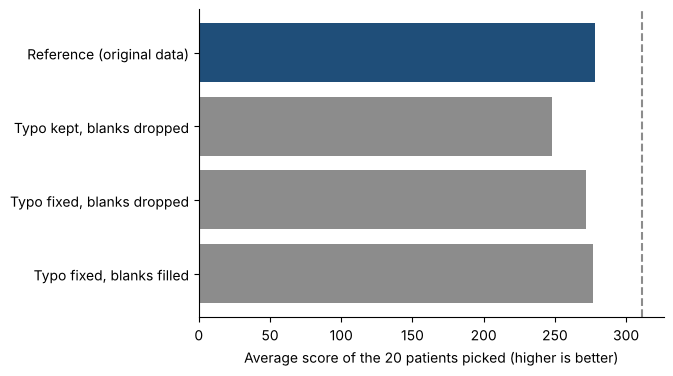

In [21]:
names = [r["Variant"] for r in results]
scores = [r["Avg score of 20 picks"] for r in results]
plt.barh(names[::-1], scores[::-1], color=[GRAY, GRAY, GRAY, BLUE])
plt.axvline(y.nlargest(20).mean(), color=GRAY, linestyle="--")
plt.xlabel("Average score of the 20 patients picked (higher is better)")
plt.show()

**Giải thích từng dòng**

- `names = [r["Variant"] for r in results]`: gom tên bốn cách làm vào một danh sách.
- `scores = [r["Avg score of 20 picks"] for r in results]`: gom điểm trung bình tương ứng.
- `plt.barh(names[::-1], scores[::-1], color=[GRAY, GRAY, GRAY, BLUE])`: `[::-1]` đảo ngược danh sách để cột tham chiếu nằm trên cùng. Tô xanh cột tham chiếu (ở vị trí cuối sau khi đảo).
- `plt.axvline(y.nlargest(20).mean(), color=GRAY, linestyle="--")`: `y.nlargest(20)` lấy 20 điểm cao nhất thật sự trong sổ. Nét đứt đánh dấu mức điểm trung bình của 20 người **thực sự** nặng nhất (mức trần mà không máy nào chạm được).

## Phán quyết và bài học nghề

**Phán quyết.**

- **Con số:** máy tham chiếu giúp chị Hạnh chọn nhóm có điểm trung bình khoảng 278 (trần lý thuyết khoảng 311). Nếu giữ ô gõ nhầm, nhóm được chọn chỉ còn khoảng 248, trùng với nhóm đúng có 12 trên 20 người, tức **8 suất rơi nhầm người**. Sửa ô gõ nhầm rồi bỏ dòng trống: khoảng 272, trùng 18 trên 20. Sửa rồi điền trung vị: khoảng 277, trùng 19 trên 20.
- **Bức tranh:** một ô gõ nhầm ngốn của chị Hạnh 8 suất quý, tức hơn một nửa số suất chọn sai. Cách "điền" thắng cách "bỏ" vì giữ được 65 bệnh án đã bị vứt oan, nhưng cả hai đều tốt hơn nhiều so với không sửa gì.
- **Khuyến nghị:** làm sạch theo công thức ba bước, rồi điền bằng trung vị. Gắn thêm bước kiểm tra tối thiểu (`duplicated`, `min`/`max`, bản đồ ô trống) trước mỗi lần xây mô hình.

**Bài học nghề.**

1. **Lỗi im lặng nguy hiểm hơn lỗi ồn ào.** Ô trống làm máy báo lỗi nên ta biết mà sửa. Ô gõ nhầm và dòng trùng thì máy cứ học, và quyết định sai âm thầm.
2. **Nhìn bằng biểu đồ trước khi tin con số.** `max()` và một biểu đồ phân tán bắt lỗi mà không cần thuật toán cao siêu nào.
3. **Đừng xóa vội.** Mỗi dòng xóa là một bệnh nhân biến mất. Hãy hỏi *vì sao ô này trống* trước khi quyết định bỏ hay điền.
4. **Điểm quá đẹp là dấu hiệu nguy hiểm.** Sai lệch 0,0 ở chặng 1 nhắc ta rằng máy chép đáp án chứ không học.

**Một điều thành thật:** hai cách làm sạch cuối chênh nhau không nhiều (272 so với 277), và ta chỉ thử trên một lần làm bẩn. Đừng kết luận điền luôn thắng bỏ, hãy so sánh trên chính dữ liệu của mình mỗi lần.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Mở sổ bằng `shape`, `info()`, `describe()` trước khi làm bất cứ điều gì. |
| 1 | Mỗi dòng là một ca, mỗi cột là một thứ đã đo. `X` là bảng đề, `y` là cột đáp án, `y` không được lẫn trong `X`. |
| 2 | Số chưa chắc là lượng: dùng `nunique()` tìm cột chỉ là mã nhóm. Cột chữ phải đổi thành số. |
| 3 | `LinearRegression` không nhận ô trống. Bỏ dòng (`dropna`) hay điền số (`fillna`) đều có cái giá. |
| 4 | Dòng trùng và số gõ nhầm làm hỏng âm thầm. Bắt bằng `duplicated()`, `max()`, `min()`, biểu đồ. |
| 5 | Làm sạch theo thứ tự: bỏ trùng, đổi số vô lý thành ô trống, rồi điền. Đo hậu quả bằng quyết định thật. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Một ca bệnh nhân | quan sát, mẫu (observation, sample) | một dòng của bảng |
| Một thứ đã đo | đặc trưng (feature) | một cột của `X` |
| Đề bài / đáp án | đặc trưng / nhãn | `X` / `y` |
| Đề bài chứa sẵn đáp án | rò rỉ dữ liệu (data leakage) | `X_leak` |
| Ô mờ không đọc được | giá trị thiếu (missing value, NaN) | `np.nan`, `isna()` |
| Bỏ ca có ô mờ / điền số hợp lý | bỏ dòng / điền khuyết (imputation) | `dropna()` / `fillna()` |
| Hai dòng giống hệt | dòng trùng (duplicate) | `duplicated()`, `drop_duplicates()` |
| Ô gõ nhầm vô lý | giá trị bất thường (outlier, anomaly) | `ledger["bmi"].max()` |
| Số chính giữa khi xếp hàng | trung vị (median) | `.median()` |

**Thử thách tự làm**

1. Đổi ngưỡng 60 ở bước `step2` thành 40 rồi chạy lại cả chặng 5. Điều gì xảy ra với số dòng bị coi là vô lý, và kết quả có thay đổi không? (Gợi ý: đếm `(step1["bmi"] > 40).sum()` trước khi đổi.)
2. Thay `step2.median()` bằng `step2.mean()` (trung bình) trong bước `fillna`. Kết quả có khác nhiều không? Vì sao trung vị thường được ưu tiên? (Gợi ý: xem `step1["bmi"].mean()` so với `.median()` trước khi sửa ô gõ nhầm.)
3. Tự làm bẩn thêm: xóa 100 ô của cột `s5` thay vì 22 ô. Làm lại chặng 3 và 5. Cách "bỏ" tệ đi đến mức nào? (Gợi ý: nhớ thêm `"s5"` vào danh sách cột và đổi `size=22` thành `size=100`.)

**Checklist năng lực** (tự tick khi làm được)

- [ ] Mở một bảng mới bằng `shape`, `info()`, `describe()` và đọc được chúng nói gì.
- [ ] Tách được `X` và `y`, và nêu được vì sao `y` không được nằm trong `X`.
- [ ] Phân biệt được cột lượng đo với cột mã nhóm.
- [ ] Đếm được ô trống, dòng trùng, và phát hiện được một số vô lý.
- [ ] Chọn và giải thích được cách xử lý ô trống: bỏ hay điền.
- [ ] Đo được hậu quả của dữ liệu bẩn bằng một quyết định cụ thể thay vì bằng một con số trừu tượng.

## Phần thưởng (Tip pro): Khi ô trống không hề ngẫu nhiên


Trong bài, ô trống rải ngẫu nhiên vì ta tự xóa ngẫu nhiên. Ngoài đời, *chính việc thiếu* thường mang thông tin: ví dụ bệnh nhân không đo huyết áp vì quá nặng, hoặc quá khỏe. Điền trung vị trong trường hợp này che mất tín hiệu quý. Mẹo của người làm nghề: **thêm một cột đánh dấu "ô này từng trống"** trước khi điền, để máy tự quyết định việc thiếu có ý nghĩa gì không.

Chạy ô dưới để tạo cột đánh dấu cho `bp`:

In [22]:
flagged = ledger.copy()
flagged["bp_was_blank"] = flagged["bp"].isna().astype(int)
flagged["bp"] = flagged["bp"].fillna(flagged["bp"].median())
flagged[["bp", "bp_was_blank"]].head(3)

,bp,bp_was_blank
0,101.0,0
1,87.0,0
2,93.0,0


**Giải thích từng dòng**

- `flagged = ledger.copy()`: bản sao để làm thử.
- `flagged["bp_was_blank"] = flagged["bp"].isna().astype(int)`: tạo cột mới: `isna()` cho Đúng/Sai, `astype(int)` đổi Đúng thành 1 và Sai thành 0. Cột này ghi nhớ *dòng nào từng trống*.
- `flagged["bp"] = flagged["bp"].fillna(flagged["bp"].median())`: điền ô trống của riêng cột `bp` bằng trung vị của cột đó. Ghi đè lại đúng cột.
- `flagged[["bp", "bp_was_blank"]].head(3)`: xem 3 dòng đầu của hai cột. Hai cặp ngoặc vuông là chọn **nhiều** cột cùng lúc.